# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
import os
from scipy import stats
os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)

df = pd.read_csv("data/AviationData_clean.csv", parse_dates=["Event.Date"], low_memory=False)
print(df.shape)
df.head()

(59150, 33)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Aboard,Fatal.Serious,Fatal.Serious.Frac,Destroyed,Plane.Type
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0.0,0.0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,0.0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0.0,0.0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0.0,0.0,PIPER PA28R200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,0.0,CESSNA 140


In [3]:
# quick structure check
print(df[["Total.Aboard", "Fatal.Serious.Frac", "Destroyed"]].describe().round(3))
print("\nEvents per year (first/last 5):")
yr = df["Event.Date"].dt.year.value_counts().sort_index()
print(pd.concat([yr.head(5), yr.tail(5)]))

       Total.Aboard  Fatal.Serious.Frac  Destroyed
count     59150.000           59150.000  58214.000
mean          4.922               0.276      0.216
std          23.676               0.431      0.412
min           1.000               0.000      0.000
25%           1.000               0.000      0.000
50%           2.000               0.000      0.000
75%           2.000               0.750      0.000
max         699.000               1.000      1.000

Events per year (first/last 5):
Event.Date
1983    2696
1984    2647
1985    2459
1986    2208
1987    2264
2018     990
2019     990
2020     858
2021     911
2022     900
Name: count, dtype: int64


In [4]:
# helper functions used throughout the notebook
_rng = np.random.default_rng(42)

def mean_ci(x, z=1.96, n_boot=2000):
    """Mean and 95% CI clipped to [0, 1].
    n < 200 : percentile bootstrap (the injury fraction is bimodal, so a normal CI is too narrow for small n)
    n >= 200: normal approximation (CLT)"""
    x = pd.Series(x).dropna().astype(float).values
    n = len(x)
    if n < 2:
        return pd.Series({"mean": x.mean() if n else np.nan, "lo": np.nan, "hi": np.nan})
    m = x.mean()
    if n < 200:
        boots = x[_rng.integers(0, n, size=(n_boot, n))].mean(axis=1)
        lo, hi = np.percentile(boots, [2.5, 97.5])
    else:
        se = x.std(ddof=1) / np.sqrt(n)
        lo, hi = m - z * se, m + z * se
    return pd.Series({"mean": m, "lo": max(0, lo), "hi": min(1, hi)})

def wilson_ci(k, n, z=1.96):
    """Wilson 95% interval for a proportion k/n (robust for small n and rates near 0 / 1)."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return (centre - half, centre + half)

def group_summary(data, by, min_n=1):
    """Per-group sample size, mean fatal/serious fraction (+CI) and destroyed rate (+Wilson CI)."""
    rows = []
    for key, g in data.groupby(by):
        n = len(g)
        if n < min_n:
            continue
        ci = mean_ci(g["Fatal.Serious.Frac"])
        d = g["Destroyed"].dropna()
        lo, hi = wilson_ci(d.sum(), len(d))
        rows.append({by: key, "n_events": n, "fs_mean": ci["mean"], "fs_lo": ci["lo"], "fs_hi": ci["hi"],
                     "n_damage_known": len(d), "destroyed_rate": d.mean() if len(d) else np.nan,
                     "dest_lo": lo, "dest_hi": hi})
    return pd.DataFrame(rows).set_index(by)

MIN_N = 30   # minimum events for a group to be compared (CLT / stability rule of thumb)

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

**How "small" vs "large" is defined**

The number of people on board in a *single* accident is a poor measure of aircraft size: a 737 can crash during a cargo/ferry flight with 2 pilots, and conversely a small Piper can be recorded with 90 people on board when it collides with an airliner (this really appears in the data: `PIPER PA-28-181`, max 90). Using the per-event maximum would therefore mislabel types. Instead we classify each **plane type** (`Make + Model`) using the **90th percentile of persons on board across all its accidents** and apply the threshold of 20:
- `Large`: p90 of persons aboard >= 20
- `Small`: otherwise

Every event inherits the class of its plane type.

In [5]:
p90 = df.groupby("Plane.Type")["Total.Aboard"].transform(lambda s: s.quantile(0.90))
df["Size"] = np.where(p90 >= 20, "Large", "Small")

print(df["Size"].value_counts())
print()
# sanity check of the classification on the most common types in each class
for sz in ["Small", "Large"]:
    print(sz, "->", df[df["Size"] == sz]["Plane.Type"].value_counts().head(6).to_dict())

small = df[df["Size"] == "Small"].copy()
large = df[df["Size"] == "Large"].copy()
print("\nMakes with >=1 small event:", small["Make"].nunique(), "| with >=1 large event:", large["Make"].nunique())

Size
Small    57660
Large     1490
Name: count, dtype: int64

Small -> {'CESSNA 152': 2213, 'CESSNA 172': 1628, 'CESSNA 172N': 1096, 'PIPER PA28140': 929, 'CESSNA 172M': 784, 'CESSNA 150': 742}
Large -> {'BOEING 737': 102, 'MCDONNELL DOUGLAS DC3': 34, 'FAIRCHILD SA227AC': 32, 'BOEING 737200': 27, 'MCDONNELL DOUGLAS MD11': 27, 'BOMBARDIER CL6002B19': 26}

Makes with >=1 small event: 50 | with >=1 large event: 11


**Important context for interpreting every number below**: the data only contains aircraft that *had an accident*. We have no flight-hours or departures, so we cannot compute accident *rates*. All fatal/serious and destruction figures are therefore **conditional on an accident having occurred** (crash severity), which is exactly what the client asked for ("in the event of an accident"). The `MIN_N = 30` rule is applied to every group comparison, and 95% confidence intervals are shown so that overlapping groups are not over-interpreted.

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [6]:
make_small = group_summary(small, "Make", MIN_N).sort_values("fs_mean")
make_large = group_summary(large, "Make", MIN_N).sort_values("fs_mean")

print(f"Small makes with >= {MIN_N} events: {len(make_small)} | Large makes with >= {MIN_N} events: {len(make_large)}")
low_small = make_small.head(15)
low_large = make_large.head(15)   # fewer than 15 large makes pass the sample-size filter, so all are shown

print("\nSMALL - 15 makes with lowest mean fatal/serious fraction")
display(low_small[["n_events", "fs_mean", "fs_lo", "fs_hi"]].round(3))
print("LARGE - makes (all that pass the sample filter)")
display(low_large[["n_events", "fs_mean", "fs_lo", "fs_hi"]].round(3))

Small makes with >= 30 events: 48 | Large makes with >= 30 events: 7

SMALL - 15 makes with lowest mean fatal/serious fraction


,n_events,fs_mean,fs_lo,fs_hi
Make,,,,
WACO,137,0.103,0.060,0.153
SCHWEIZER,127,0.142,0.087,0.205
HELIO,105,0.150,0.087,0.216
MAULE,569,0.154,0.126,0.182
GRUMMAN-SCHWEIZER,188,0.155,0.105,0.209
GREAT LAKES,58,0.164,0.069,0.259
BOEING,422,0.179,0.145,0.213
BOEING STEARMAN,50,0.180,0.080,0.280
WEATHERLY,85,0.188,0.106,0.271


LARGE - makes (all that pass the sample filter)


,n_events,fs_mean,fs_lo,fs_hi
Make,,,,
BOMBARDIER,65,0.106,0.043,0.176
BOEING,794,0.125,0.103,0.146
EMBRAER,94,0.129,0.073,0.194
AIRBUS,150,0.130,0.082,0.181
MCDONNELL DOUGLAS,261,0.139,0.100,0.177
FAIRCHILD,38,0.179,0.077,0.291
DE HAVILLAND,45,0.232,0.125,0.355


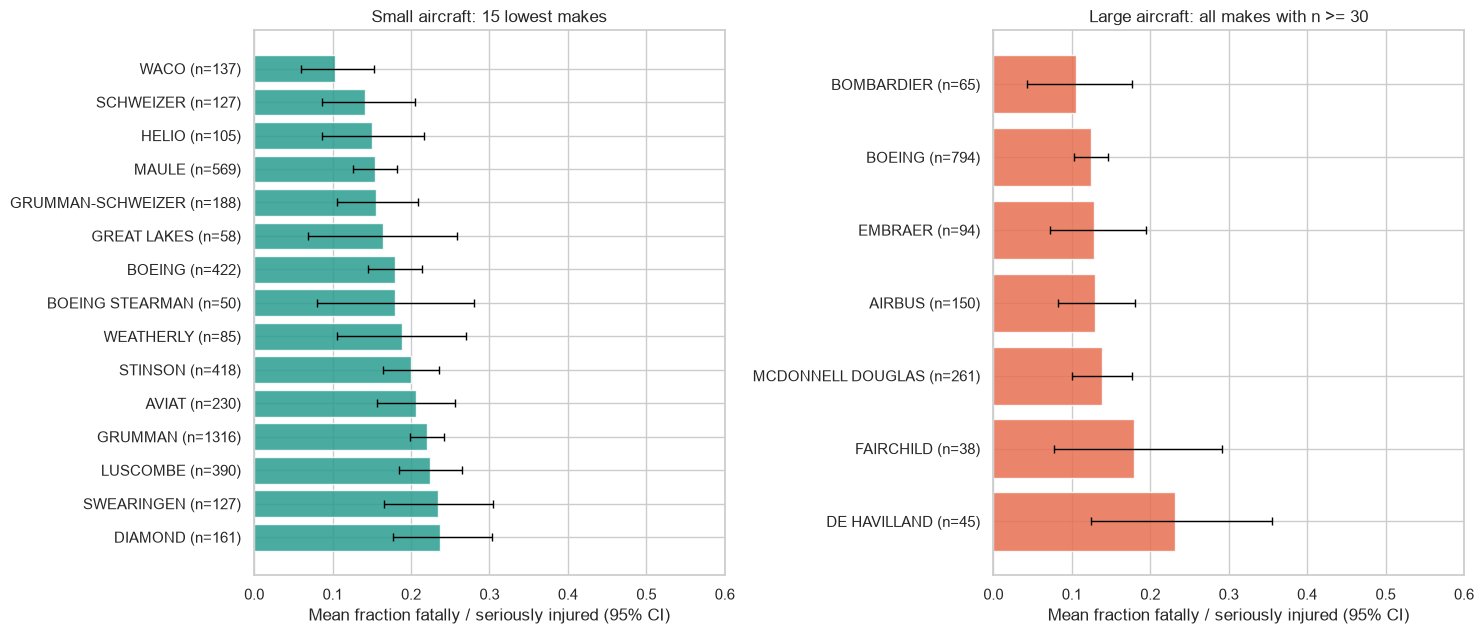

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, tab, title, col in [(axes[0], low_small, "Small aircraft: 15 lowest makes", "#2a9d8f"),
                            (axes[1], low_large, f"Large aircraft: all makes with n >= {MIN_N}", "#e76f51")]:
    y = np.arange(len(tab))
    ax.barh(y, tab["fs_mean"], color=col, alpha=0.85)
    ax.errorbar(tab["fs_mean"], y, xerr=[tab["fs_mean"] - tab["fs_lo"], tab["fs_hi"] - tab["fs_mean"]],
                fmt="none", ecolor="black", capsize=3, lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{m} (n={int(n)})" for m, n in zip(tab.index, tab["n_events"])])
    ax.invert_yaxis()
    ax.set_xlabel("Mean fraction fatally / seriously injured (95% CI)")
    ax.set_title(title)
    ax.set_xlim(0, 0.6)
plt.tight_layout()
plt.savefig("images/make_injury_fraction.png", dpi=150, bbox_inches="tight")
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

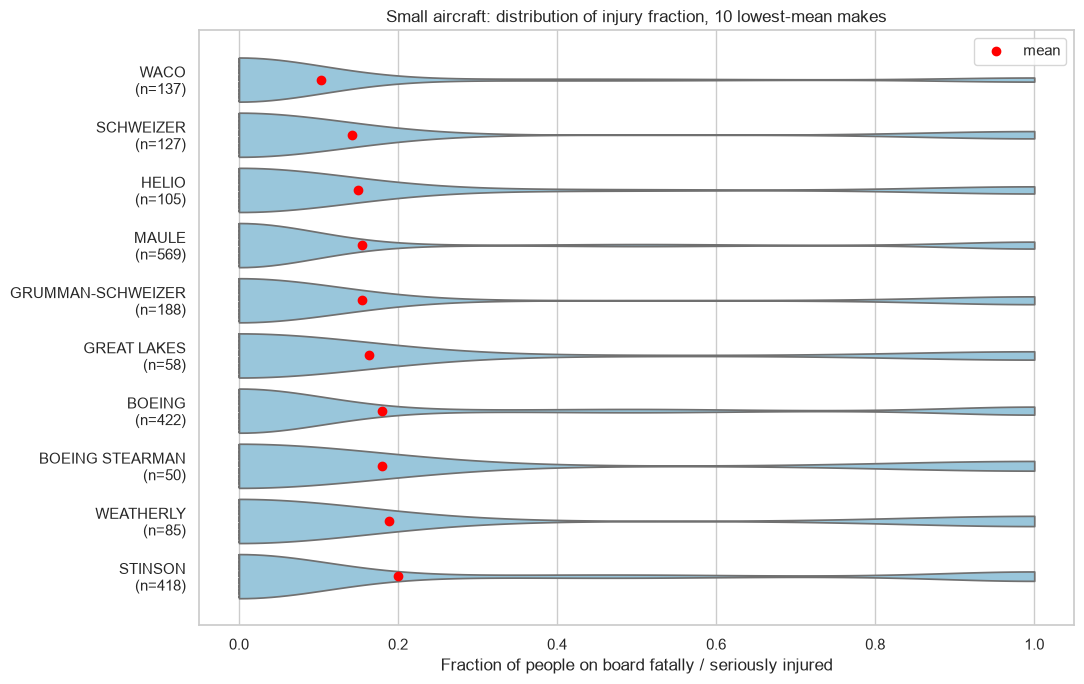

,n,share_zero,share_all,median
Make,,,,
WACO,137,0.869,0.080,0.0
SCHWEIZER,127,0.858,0.142,0.0
HELIO,105,0.819,0.133,0.0
MAULE,569,0.819,0.128,0.0
GRUMMAN-SCHWEIZER,188,0.840,0.149,0.0
GREAT LAKES,58,0.828,0.155,0.0
BOEING,422,0.765,0.140,0.0
BOEING STEARMAN,50,0.820,0.180,0.0
WEATHERLY,85,0.812,0.188,0.0


In [8]:
top10_small = make_small.head(10).index.tolist()
sdat = small[small["Make"].isin(top10_small)]
labels = {m: f"{m}\n(n={int(make_small.loc[m, 'n_events'])})" for m in top10_small}

plt.figure(figsize=(11, 7))
ax = sns.violinplot(data=sdat, y="Make", x="Fatal.Serious.Frac", order=top10_small, orient="h",
                    cut=0, inner="quartile", density_norm="width", color="#8ecae6") if "density_norm" in sns.violinplot.__code__.co_varnames \
     else sns.violinplot(data=sdat, y="Make", x="Fatal.Serious.Frac", order=top10_small, orient="h",
                         cut=0, inner="quartile", scale="width", color="#8ecae6")
ax.scatter(make_small.loc[top10_small, "fs_mean"], range(10), color="red", zorder=5, label="mean")
ax.set_yticks(range(10)); ax.set_yticklabels([labels[m] for m in top10_small])
ax.set_xlabel("Fraction of people on board fatally / seriously injured"); ax.set_ylabel("")
ax.set_title("Small aircraft: distribution of injury fraction, 10 lowest-mean makes")
ax.legend(); plt.tight_layout()
plt.savefig("images/small_violin.png", dpi=150, bbox_inches="tight"); plt.show()

# the violins are bimodal, so show the share of "no one badly hurt" vs "everyone badly hurt" accidents
shares = sdat.groupby("Make")["Fatal.Serious.Frac"].agg(
    n="size", share_zero=lambda s: (s == 0).mean(), share_all=lambda s: (s == 1).mean(),
    median="median").loc[top10_small]
display(shares.round(3))

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

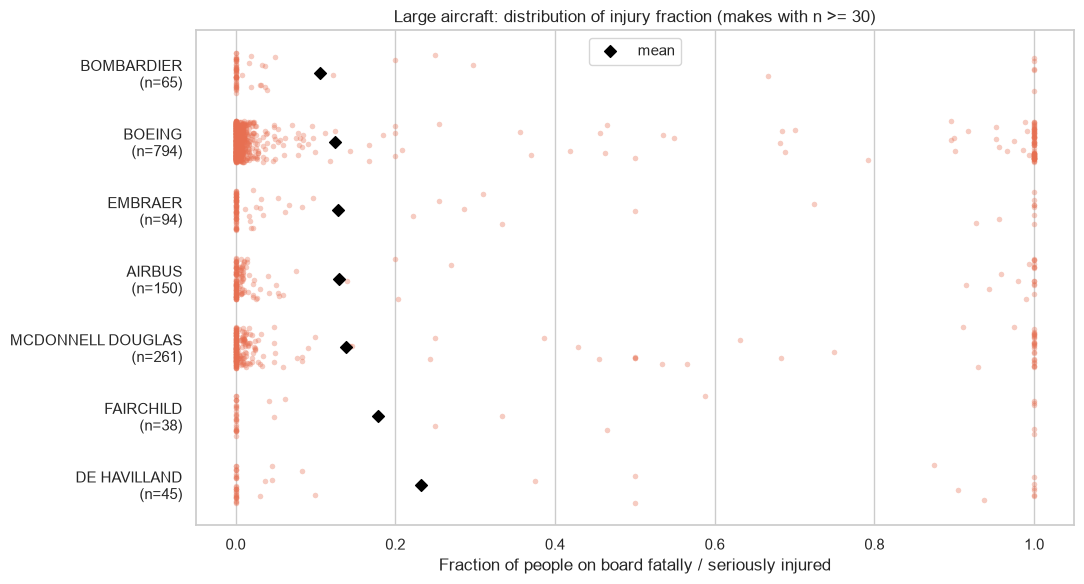

,n,share_zero,share_all,median
Make,,,,
BOMBARDIER,65,0.677,0.077,0.000
BOEING,794,0.489,0.089,0.003
EMBRAER,94,0.670,0.074,0.000
AIRBUS,150,0.500,0.080,0.002
MCDONNELL DOUGLAS,261,0.513,0.096,0.000
FAIRCHILD,38,0.684,0.132,0.000
DE HAVILLAND,45,0.600,0.133,0.000


Kruskal-Wallis across large makes: H = 6.97, p = 0.3238


In [9]:
top10_large = make_large.head(10).index.tolist()
ldat = large[large["Make"].isin(top10_large)]

plt.figure(figsize=(11, 6))
ax = sns.stripplot(data=ldat, y="Make", x="Fatal.Serious.Frac", order=top10_large, orient="h",
                   jitter=0.3, alpha=0.35, size=4, color="#e76f51")
ax.scatter(make_large.loc[top10_large, "fs_mean"], range(len(top10_large)), color="black", marker="D", zorder=5, label="mean")
ax.set_yticks(range(len(top10_large)))
ax.set_yticklabels([f"{m}\n(n={int(make_large.loc[m, 'n_events'])})" for m in top10_large])
ax.set_xlabel("Fraction of people on board fatally / seriously injured"); ax.set_ylabel("")
ax.set_title(f"Large aircraft: distribution of injury fraction (makes with n >= {MIN_N})")
ax.legend(); plt.tight_layout()
plt.savefig("images/large_strip.png", dpi=150, bbox_inches="tight"); plt.show()

shares = ldat.groupby("Make")["Fatal.Serious.Frac"].agg(
    n="size", share_zero=lambda s: (s == 0).mean(), share_all=lambda s: (s == 1).mean(), median="median").loc[top10_large]
display(shares.round(3))

# is the difference between large makes statistically distinguishable?
groups = [g["Fatal.Serious.Frac"].values for _, g in ldat.groupby("Make")]
print("Kruskal-Wallis across large makes: H = %.2f, p = %.4f" % stats.kruskal(*groups))

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

SMALL - lowest destroyed fraction by make


,n_damage_known,destroyed_rate,dest_lo,dest_hi
Make,,,,
AVIAT,229,0.070,0.043,0.110
DIAMOND,161,0.075,0.043,0.126
WACO,137,0.088,0.051,0.147
MAULE,568,0.093,0.072,0.120
BOEING STEARMAN,50,0.100,0.043,0.214
LUSCOMBE,386,0.104,0.077,0.138
TAYLORCRAFT,366,0.123,0.093,0.161
HELIO,104,0.125,0.075,0.202
STINSON,418,0.134,0.105,0.170


LARGE - lowest destroyed fraction by make


,n_damage_known,destroyed_rate,dest_lo,dest_hi
Make,,,,
BOMBARDIER,50,0.120,0.056,0.238
EMBRAER,61,0.180,0.104,0.295
BOEING,446,0.211,0.175,0.251
MCDONNELL DOUGLAS,203,0.217,0.166,0.278
FAIRCHILD,36,0.250,0.138,0.411
DE HAVILLAND,39,0.282,0.165,0.438
AIRBUS,74,0.284,0.194,0.395


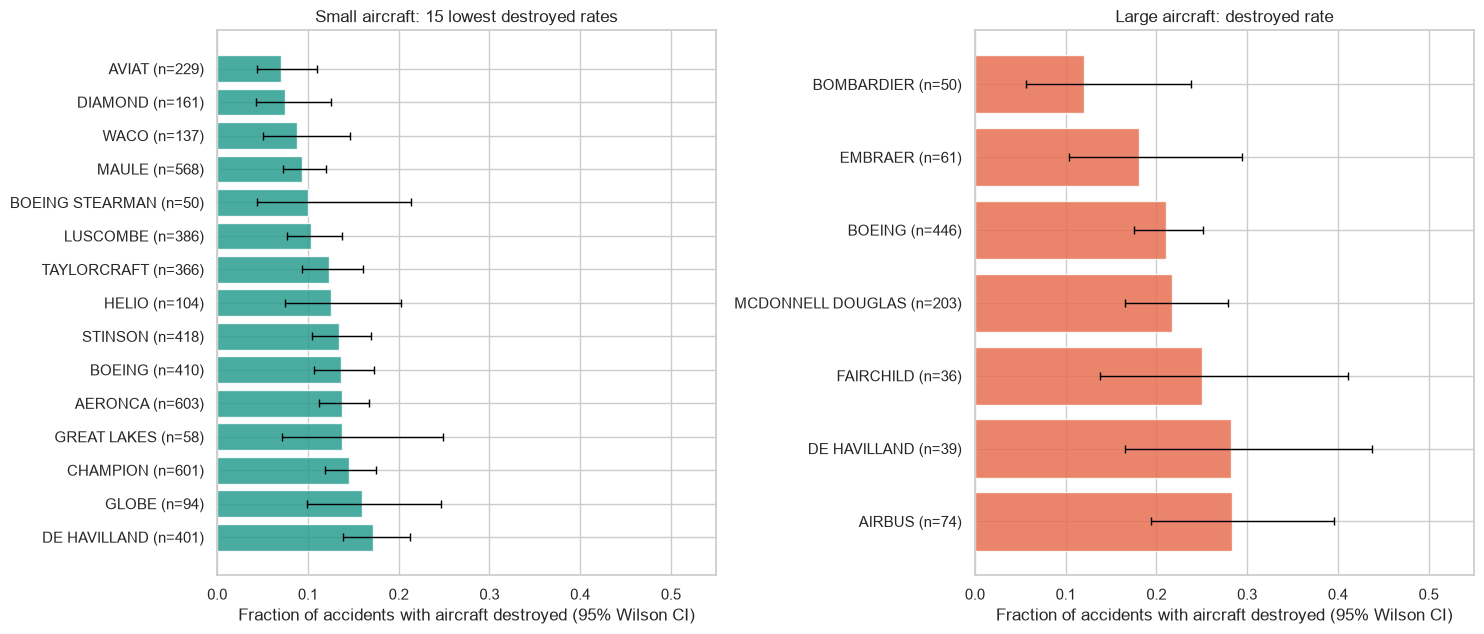

Combined ranking (small): average of injury-rank and destroyed-rank


,n_events,fs_mean,destroyed_rate,rank_injury,rank_destroyed,avg_rank
Make,,,,,,
WACO,137,0.103,0.088,1.0,3.0,2.0
MAULE,569,0.154,0.093,4.0,4.0,4.0
HELIO,105,0.150,0.125,3.0,8.0,5.5
AVIAT,230,0.207,0.070,11.0,1.0,6.0
BOEING STEARMAN,50,0.180,0.100,8.0,5.0,6.5
BOEING,422,0.179,0.137,7.0,10.0,8.5
DIAMOND,161,0.237,0.075,15.0,2.0,8.5
GREAT LAKES,58,0.164,0.138,6.0,12.0,9.0
LUSCOMBE,390,0.224,0.104,13.0,6.0,9.5


Combined ranking (large): average of injury-rank and destroyed-rank


,n_events,fs_mean,destroyed_rate,rank_injury,rank_destroyed,avg_rank
Make,,,,,,
BOMBARDIER,65,0.106,0.120,1.0,1.0,1.0
BOEING,794,0.125,0.211,2.0,3.0,2.5
EMBRAER,94,0.129,0.180,3.0,2.0,2.5
MCDONNELL DOUGLAS,261,0.139,0.217,5.0,4.0,4.5
AIRBUS,150,0.130,0.284,4.0,7.0,5.5
FAIRCHILD,38,0.179,0.250,6.0,5.0,5.5
DE HAVILLAND,45,0.232,0.282,7.0,6.0,6.5


In [10]:
dest_small = group_summary(small, "Make", MIN_N).dropna(subset=["destroyed_rate"]).sort_values("destroyed_rate").head(15)
dest_large = group_summary(large, "Make", MIN_N).dropna(subset=["destroyed_rate"]).sort_values("destroyed_rate").head(15)

cols = ["n_damage_known", "destroyed_rate", "dest_lo", "dest_hi"]
print("SMALL - lowest destroyed fraction by make"); display(dest_small[cols].round(3))
print("LARGE - lowest destroyed fraction by make"); display(dest_large[cols].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, tab, title, col in [(axes[0], dest_small, "Small aircraft: 15 lowest destroyed rates", "#2a9d8f"),
                            (axes[1], dest_large, "Large aircraft: destroyed rate", "#e76f51")]:
    y = np.arange(len(tab))
    ax.barh(y, tab["destroyed_rate"], color=col, alpha=0.85)
    ax.errorbar(tab["destroyed_rate"], y, xerr=[tab["destroyed_rate"] - tab["dest_lo"], tab["dest_hi"] - tab["destroyed_rate"]],
                fmt="none", ecolor="black", capsize=3, lw=1)
    ax.set_yticks(y); ax.set_yticklabels([f"{m} (n={int(n)})" for m, n in zip(tab.index, tab["n_damage_known"])])
    ax.invert_yaxis(); ax.set_xlabel("Fraction of accidents with aircraft destroyed (95% Wilson CI)")
    ax.set_title(title); ax.set_xlim(0, 0.55)
plt.tight_layout(); plt.savefig("images/make_destroyed_rate.png", dpi=150, bbox_inches="tight"); plt.show()

# combined view: makes that are good on BOTH criteria
comb_s = make_small[["n_events", "fs_mean"]].join(group_summary(small, "Make", MIN_N)[["destroyed_rate"]])
comb_l = make_large[["n_events", "fs_mean"]].join(group_summary(large, "Make", MIN_N)[["destroyed_rate"]])
for name, c in [("small", comb_s), ("large", comb_l)]:
    c["rank_injury"] = c["fs_mean"].rank(); c["rank_destroyed"] = c["destroyed_rate"].rank()
    c["avg_rank"] = (c["rank_injury"] + c["rank_destroyed"]) / 2
    print(f"Combined ranking ({name}): average of injury-rank and destroyed-rank")
    display(c.sort_values("avg_rank").head(10).round(3))

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [11]:
# ---- statistical robustness checks for the make-level conclusions ----
def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1, run)
    return adj

# SMALL: each of the 10 best makes vs ALL OTHER small aircraft (Mann-Whitney on injury fraction, chi-square on destroyed)
rows = []
for m in top10_small:
    a = small[small["Make"] == m]; b = small[small["Make"] != m]
    p_inj = stats.mannwhitneyu(a["Fatal.Serious.Frac"], b["Fatal.Serious.Frac"], alternative="less").pvalue
    ad, bd = a["Destroyed"].dropna(), b["Destroyed"].dropna()
    ct = [[ad.sum(), len(ad) - ad.sum()], [bd.sum(), len(bd) - bd.sum()]]
    p_des = stats.chi2_contingency(ct)[1] if ad.mean() < bd.mean() else 1.0
    rows.append({"Make": m, "n": len(a), "mean_fs": a["Fatal.Serious.Frac"].mean(), "mean_fs_others": b["Fatal.Serious.Frac"].mean(),
                 "p_injury": p_inj, "dest": ad.mean(), "dest_others": bd.mean(), "p_destroyed": p_des})
rob = pd.DataFrame(rows).set_index("Make")
rob["p_injury_holm"] = holm(rob["p_injury"]); rob["p_destroyed_holm"] = holm(rob["p_destroyed"])
print("SMALL makes vs the rest of the small fleet (one-sided; Holm-adjusted across the 10 tests)")
display(rob.round(4))

# LARGE: are the makes distinguishable at all?
chi_ct = pd.crosstab(large[large["Make"].isin(make_large.index)]["Make"], large["Destroyed"])
chi2, p, dof, _ = stats.chi2_contingency(chi_ct)
print(f"LARGE makes - destroyed rate differs between makes? chi-square({dof}) = {chi2:.2f}, p = {p:.3f}")
kw = stats.kruskal(*[g["Fatal.Serious.Frac"].values for _, g in large[large["Make"].isin(make_large.index)].groupby("Make")])
print(f"LARGE makes - injury fraction differs between makes? Kruskal-Wallis H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}")


SMALL makes vs the rest of the small fleet (one-sided; Holm-adjusted across the 10 tests)


,n,mean_fs,mean_fs_others,p_injury,dest,dest_others,p_destroyed,p_injury_holm,p_destroyed_holm
Make,,,,,,,,,
WACO,137,0.1034,0.2797,0.0000,0.0876,0.2163,0.0004,0.0000,0.0027
SCHWEIZER,127,0.1417,0.2796,0.0001,0.2283,0.2159,1.0000,0.0003,1.0000
HELIO,105,0.1501,0.2795,0.0015,0.1250,0.2161,0.0326,0.0059,0.1955
MAULE,569,0.1542,0.2806,0.0000,0.0933,0.2172,0.0000,0.0000,0.0000
GRUMMAN-SCHWEIZER,188,0.1551,0.2797,0.0000,0.1765,0.2161,0.2203,0.0001,0.7947
GREAT LAKES,58,0.1638,0.2794,0.0146,0.1379,0.2160,0.1987,0.0412,0.7947
BOEING,422,0.1794,0.2800,0.0000,0.1366,0.2165,0.0001,0.0001,0.0009
BOEING STEARMAN,50,0.1800,0.2794,0.0342,0.1000,0.2161,0.0685,0.0412,0.3425
WEATHERLY,85,0.1882,0.2794,0.0137,0.2118,0.2160,1.0000,0.0412,1.0000


LARGE makes - destroyed rate differs between makes? chi-square(6) = 6.52, p = 0.368
LARGE makes - injury fraction differs between makes? Kruskal-Wallis H = 6.97, p = 0.324


### Discussion: makes

**Baselines.** Across all small aircraft in the cleaned data, an accident leaves on average **27.9%** of the people on board fatally or seriously injured and destroys the aircraft **21.6%** of the time. For large aircraft the corresponding figures are **13.5%** and **21.8%**. Large aircraft are far more survivable *per accident*, but are destroyed just as often.

**Small aircraft - recommended makes**
- **Maule** is the best-supported recommendation: with 569 events it has the largest sample among the top makes, a mean fatal/serious fraction of **0.154** (95% CI 0.126-0.182) and the lowest-tier destroyed rate (**9.3%** vs 21.7% for all other small aircraft). Both differences remain significant after Holm correction for multiple testing (p < 0.001).
- **Waco** (0.103, n=137) has the lowest injury fraction of any make and a destroyed rate of 8.8%; **Helio** (0.150, n=105) and **Schweizer / Grumman-Schweizer** (0.142 / 0.155) also have significantly lower injury fractions than the rest of the fleet, but their *destruction* rates are not distinguishable from average (Schweizer 22.8%, Grumman-Schweizer 17.6%; Holm p > 0.19), so they protect people better than they protect the airframe.
- **Aviat** (7.0%) and **Diamond** (7.5%) have the lowest destruction rates of any small make, but their injury fractions (0.207 and 0.237) are only slightly better than average, so we would rate them as good for *hull* risk, only fair for *occupant* risk.
- Large-volume makes land in the middle: **Cessna** (0.245 injury, 19.1% destroyed; n=25,368) is better than **Piper** (0.302, 23.1%; n=13,945), and both are far better than **Cirrus** (0.457), **Mitsubishi** (0.505), **Socata** (0.416), **Beech** (0.379, 30.6% destroyed) and **Aero Commander** (0.387, 34.0% destroyed).

**Small aircraft - how to read the distributions.** The violin plots are strongly *bimodal*: for the 10 best makes, 76-87% of accidents leave nobody seriously hurt (fraction = 0) and 8-19% leave everybody seriously or fatally hurt (fraction = 1); very few are in between because most small aircraft carry only 1-3 people. The mean is therefore driven almost entirely by the **share of catastrophic accidents** (Waco 8% vs Stinson 16%), not by partial injuries. This is why we used rank-based tests (Mann-Whitney / Kruskal-Wallis) rather than comparing means alone.

**Large aircraft - recommended makes**
- Only 11 makes have any large-aircraft accidents and just **7 pass the n >= 30 filter**, so fewer than 15 can be shown. Their mean fatal/serious fractions are: **Bombardier 0.106, Boeing 0.125, Embraer 0.129, Airbus 0.130, McDonnell Douglas 0.139, Fairchild 0.179, De Havilland 0.232**. The destroyed rates range from 12.0% (Bombardier) to about 28% (Airbus, De Havilland).
- **Statistical caveat (important):** these makes are **not statistically distinguishable** - the Kruskal-Wallis test on injury fraction gives p = 0.32 and the chi-square test on destruction gives p = 0.37, and the confidence intervals of all seven overlap. The stripplot shows the same thing: every make has a cluster at ~0 (49-68% of accidents) and a thin spread up to 1.
- Our recommendation is therefore to treat **Boeing, Airbus, Embraer, Bombardier and McDonnell Douglas** as a single comparable low-risk tier (Boeing has by far the strongest evidence, n=794), and to *not* claim that one of them is safer than another on this data. Fairchild (Metro/Swearingen commuter turboprops) and De Havilland (DHC-6/-8 turboprops) are less favourable, but their samples (38 and 45) are too small to be conclusive - their smaller, commuter-class aircraft also operate in harsher conditions than airliners.

**Caveats.** (1) The data has no exposure, so these are *severity-given-accident* figures, not accident rates. (2) Several top small makes are vintage or niche designs (Waco, Stearman = `BOEING` small, Stinson, Luscombe) flown slowly and in benign conditions, so low-energy crashes partly explain their results. (3) Where a make's fraction is low because it is used differently (agricultural, aerobatic, sport), the factors analysed at the end of the notebook should be kept in mind.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [12]:
types_large = group_summary(large, "Plane.Type", min_n=10).sort_values("fs_mean")
print(f"Large plane types with >= 10 events: {len(types_large)}")
display(types_large[["n_events", "fs_mean", "fs_lo", "fs_hi", "destroyed_rate"]].round(3).head(25))

Large plane types with >= 10 events: 36


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate
Plane.Type,,,,,
BOEING 717200,11,0.002,0.000,0.004,0.000
BOEING 757223,11,0.004,0.001,0.007,0.000
BOEING 757232,17,0.005,0.003,0.008,0.000
MCDONNELL DOUGLAS MD88,18,0.006,0.003,0.010,0.000
AIRBUS A320232,12,0.006,0.003,0.010,0.000
BOEING 757222,11,0.007,0.002,0.014,0.000
MCDONNELL DOUGLAS MD80,11,0.010,0.002,0.023,0.000
BOMBARDIER CL6002C10,16,0.027,0.002,0.063,0.000
EMBRAER EMB145LR,16,0.043,0.004,0.111,0.000


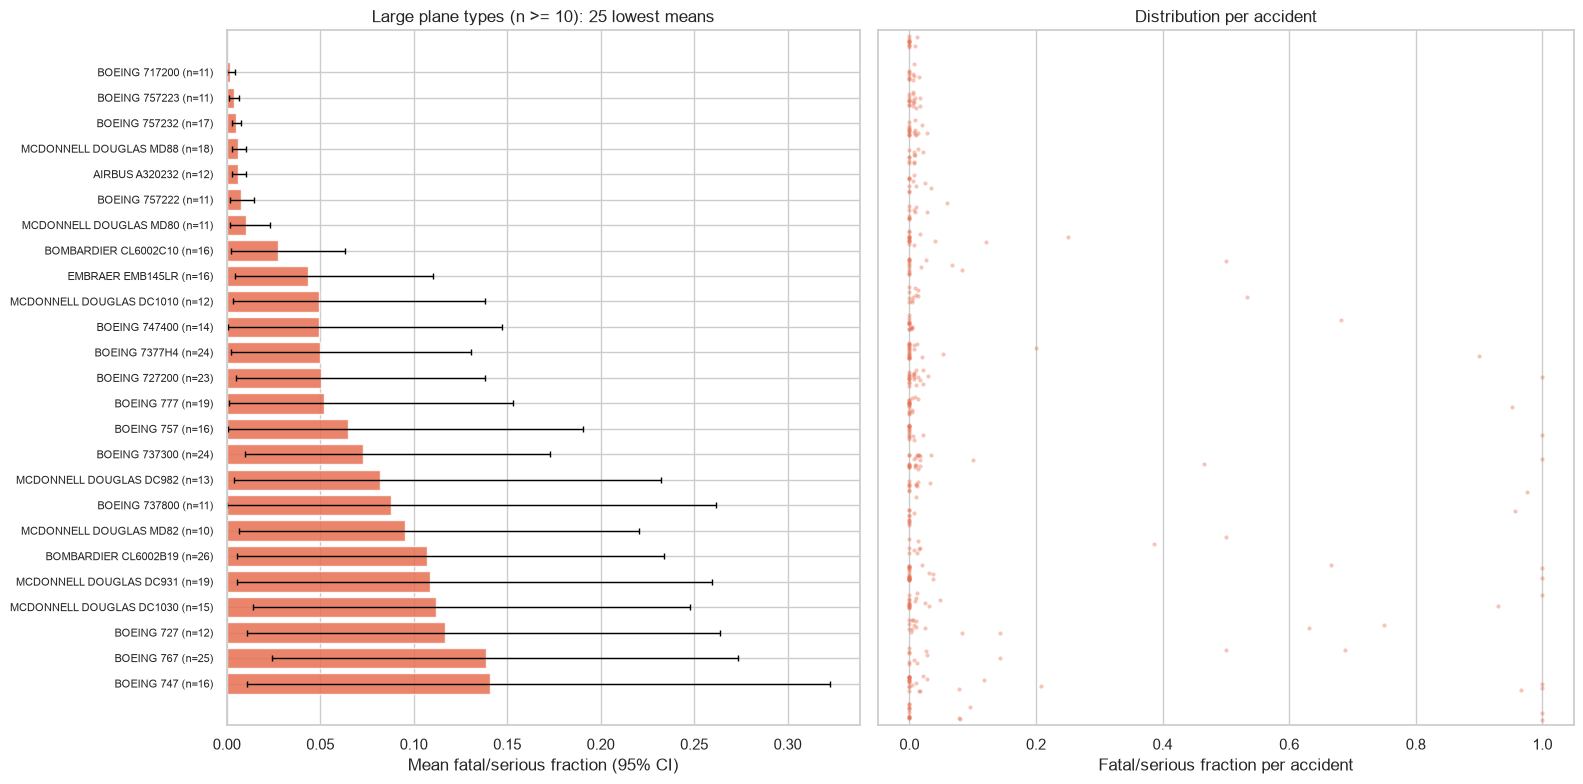

In [13]:
tl = types_large.head(25)
fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1, 1.1]})
y = np.arange(len(tl))
axes[0].barh(y, tl["fs_mean"], color="#e76f51", alpha=0.85)
axes[0].errorbar(tl["fs_mean"], y, xerr=[tl["fs_mean"] - tl["fs_lo"], tl["fs_hi"] - tl["fs_mean"]], fmt="none", ecolor="black", capsize=2, lw=1)
axes[0].set_yticks(y); axes[0].set_yticklabels([f"{t} (n={int(n)})" for t, n in zip(tl.index, tl["n_events"])], fontsize=8)
axes[0].invert_yaxis(); axes[0].set_xlabel("Mean fatal/serious fraction (95% CI)"); axes[0].set_title("Large plane types (n >= 10): 25 lowest means")

sns.stripplot(data=large[large["Plane.Type"].isin(tl.index)], y="Plane.Type", x="Fatal.Serious.Frac", order=tl.index,
              orient="h", jitter=0.3, alpha=0.4, size=3, color="#e76f51", ax=axes[1])
axes[1].set_ylabel(""); axes[1].set_yticklabels([]); axes[1].set_xlabel("Fatal/serious fraction per accident")
axes[1].set_title("Distribution per accident")
plt.tight_layout(); plt.savefig("images/large_types.png", dpi=150, bbox_inches="tight"); plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [14]:
# restrict to plane types from the 10 small makes with the lowest mean fraction, then require >= 10 events per type
types_small = group_summary(small[small["Make"].isin(top10_small)], "Plane.Type", min_n=10).sort_values("fs_mean")
types_small["Make"] = [t.split(" ")[0] if t.split(" ")[0] in top10_small else next(m for m in top10_small if t.startswith(m + " ")) for t in types_small.index]
print(f"Small plane types (from the 10 best makes) with >= 10 events: {len(types_small)}")
display(types_small[["n_events", "fs_mean", "fs_lo", "fs_hi", "destroyed_rate"]].round(3).head(25))

Small plane types (from the 10 best makes) with >= 10 events: 45


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate
Plane.Type,,,,,
HELIO H391B,11,0.000,0.000,0.000,0.091
MAULE MX7235,24,0.021,0.000,0.062,0.042
MAULE M4,26,0.038,0.000,0.115,0.038
WEATHERLY 201B,29,0.069,0.000,0.172,0.103
BOEING STEARMAN A75N1,14,0.071,0.000,0.214,0.071
BOEING E75,33,0.076,0.000,0.182,0.121
MAULE MX7180,13,0.077,0.000,0.231,0.000
WACO YMF5,10,0.083,0.000,0.200,0.100
GREAT LAKES 2T1A,11,0.091,0.000,0.273,0.091


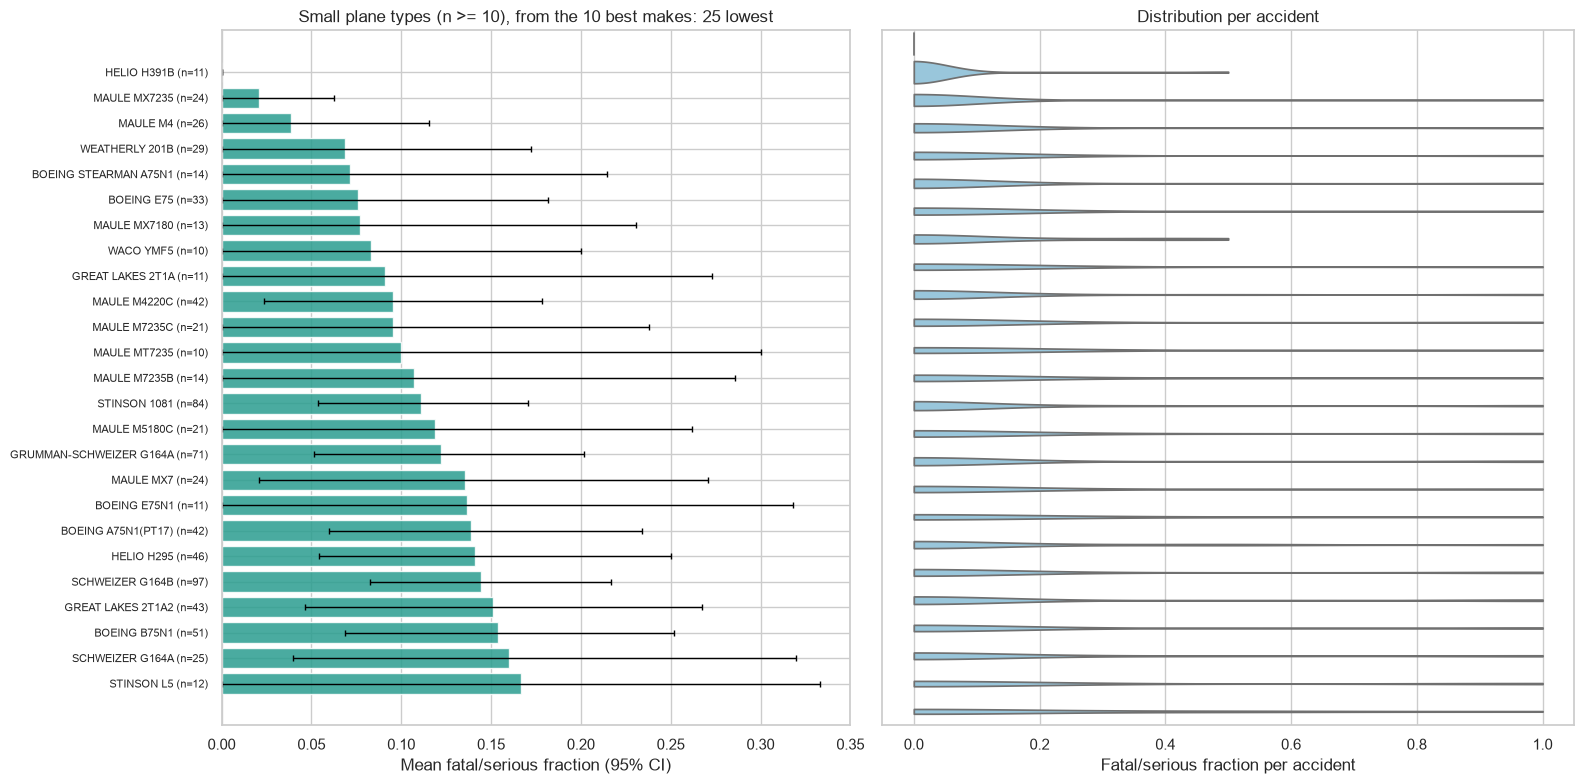

In [15]:
ts = types_small.head(25)
fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1, 1.1]})
y = np.arange(len(ts))
axes[0].barh(y, ts["fs_mean"], color="#2a9d8f", alpha=0.85)
axes[0].errorbar(ts["fs_mean"], y, xerr=[ts["fs_mean"] - ts["fs_lo"], ts["fs_hi"] - ts["fs_mean"]], fmt="none", ecolor="black", capsize=2, lw=1)
axes[0].set_yticks(y); axes[0].set_yticklabels([f"{t} (n={int(n)})" for t, n in zip(ts.index, ts["n_events"])], fontsize=8)
axes[0].invert_yaxis(); axes[0].set_xlabel("Mean fatal/serious fraction (95% CI)")
axes[0].set_title("Small plane types (n >= 10), from the 10 best makes: 25 lowest")

sns.violinplot(data=small[small["Plane.Type"].isin(ts.index)], y="Plane.Type", x="Fatal.Serious.Frac", order=ts.index,
               orient="h", cut=0, inner=None, color="#8ecae6", ax=axes[1])
axes[1].set_ylabel(""); axes[1].set_yticklabels([]); axes[1].set_xlabel("Fatal/serious fraction per accident")
axes[1].set_title("Distribution per accident")
plt.tight_layout(); plt.savefig("images/small_types.png", dpi=150, bbox_inches="tight"); plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Large-aircraft model FAMILIES with >= 30 events


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Family,,,,,,,
BOEING 757,89,0.051,0.016,0.096,0.103,0.041,0.236
BOEING 777,51,0.071,0.013,0.145,0.211,0.085,0.433
BOMBARDIER CL600,52,0.073,0.023,0.139,0.075,0.026,0.199
BOEING 727,92,0.097,0.049,0.154,0.143,0.077,0.250
BOEING 767,79,0.110,0.049,0.179,0.189,0.095,0.342
BOEING 747,82,0.111,0.050,0.177,0.143,0.074,0.257
MCDONNELL DOUGLAS MD11,36,0.125,0.043,0.229,0.226,0.114,0.398
BOEING 737,321,0.137,0.101,0.172,0.237,0.181,0.305
FAIRCHILD SA227,32,0.148,0.051,0.257,0.226,0.114,0.398


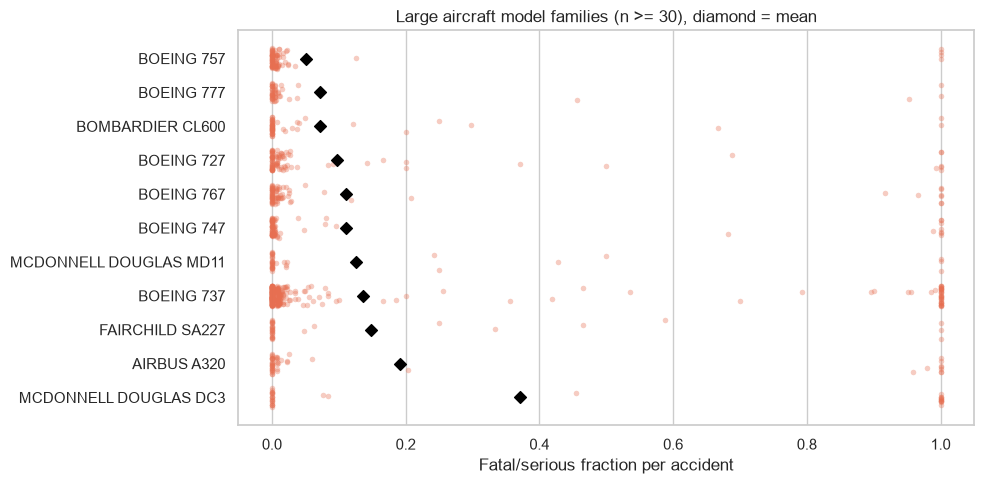

In [16]:
# Model-family roll-up for large aircraft (variants such as 737-300/-700/-800 individually have too few events)
fam = large.copy()
fam["Family"] = fam["Plane.Type"].str.extract(r"^(BOEING 7\d7|AIRBUS A3\d\d|MCDONNELL DOUGLAS (?:DC\d+|MD\d+)|BOMBARDIER CL600|EMBRAER EMB\d+|BEECH 1900|DE HAVILLAND DHC\d+|FAIRCHILD SA22\d)")[0]
fam_tab = group_summary(fam.dropna(subset=["Family"]), "Family", min_n=30).sort_values("fs_mean")
print("Large-aircraft model FAMILIES with >= 30 events")
display(fam_tab[["n_events", "fs_mean", "fs_lo", "fs_hi", "destroyed_rate", "dest_lo", "dest_hi"]].round(3))

# distribution check for the largest families
ford = fam_tab.index.tolist()
plt.figure(figsize=(10, 5))
sns.stripplot(data=fam[fam["Family"].isin(ford)], y="Family", x="Fatal.Serious.Frac", order=ford, jitter=0.3, alpha=0.35, size=4, color="#e76f51")
plt.scatter(fam_tab["fs_mean"], range(len(ford)), color="black", marker="D", zorder=5)
plt.xlabel("Fatal/serious fraction per accident"); plt.ylabel(""); plt.title("Large aircraft model families (n >= 30), diamond = mean")
plt.tight_layout(); plt.savefig("images/large_families.png", dpi=150, bbox_inches="tight"); plt.show()

### Discussion: specific airplane types

**Large aircraft (36 types with >= 10 events; family roll-up with n >= 30 shown above)**
- The *lowest injury fractions* belong to modern narrow-body and mid-size jets: **Boeing 717-200 (0.002, n=11), Boeing 757-223 (0.004, n=11), 757-232 (0.005, n=17), McDonnell Douglas MD-88 (0.006, n=18), Airbus A320-232 (0.006, n=12), Boeing 757-222 (0.007, n=11) and MD-80 (0.010, n=11)**. All of these also have a **0% destroyed rate**. At the family level the **Boeing 757 (n=89)** is the best-supported result: mean fraction **0.051** and only **10.3%** destroyed, followed by the **777 (0.071, n=51)**, the **Bombardier CL-600 family (0.073, n=52, 7.5% destroyed)**, **727 (0.097)**, **767 (0.110)**, **747 (0.111)** and **737 family (0.137, n=321)**.
- Single-variant results rest on 10-30 events and the bootstrap CIs overlap widely (e.g. 757-223 vs 747-400 vs 777), so the *tier* is more reliable than the exact rank. We therefore recommend the **Boeing 757, 717-200, 777, MD-80/88 and A320-232** as the preferred large types, with the 767/747/737-800/-300 as acceptable.
- *Less favourable* types with a reasonable sample: **Boeing 737-200 (0.375, 57.9% destroyed, n=27)** and **737-400 (0.324, n=12)** - older-generation 737s; **Airbus A320 (unspecified variant; 0.373, 66.7% destroyed, n=16)**; **DC-3 (0.371, n=34)** - a 1930s-design piston airliner that is hardly an airline asset today; **DHC-6-300 Twin Otter (0.311)** and **Beech 1900 (0.380, n=14)**, which are commuter aircraft operating in rougher conditions.

**Small aircraft (45 types with >= 10 events within the 10 best makes)**
- **Maule models dominate the bottom of the table**: **MX-7-235 (0.021, n=24), M-4 (0.038, n=26), MX-7-180 (0.077, n=13), M-4-220C (0.095, n=42), M-7-235C (0.095, n=21)** with destroyed rates of 0-10%. Because this is true across *many* Maule variants it is a consistent make-level signal, not a single-model fluke.
- Other strong small types are the **Stinson 108-1 (0.111, n=84)**, **Helio H-295 (0.141, n=46)** and **H-391B (0.000, n=11)**, **Weatherly 201B (0.069, n=29)** and **Grumman-Schweizer G-164A (0.122, n=71)** (agricultural), and the vintage **Stearman** variants (**A75N1 0.071**, **E75 0.076**, **PT-17 0.139**, **B75N1 0.154**), which are listed under `BOEING` in the data.
- As the violin plots show, these distributions are bimodal and the confidence intervals are wide (for n < 30 the lower bound is often 0), so individual types should be taken as *indicative*; the Maule family (n > 150 events combined) is the only small-aircraft recommendation backed by clear statistical separation from the rest of the fleet.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

We analyse **four** of the five suggested factors: **Weather Condition**, **Phase of Flight**, **Number of Engines** and **Purpose of Flight** (Engine Type is covered inside the engine analysis). For each one we show (1) a summary table with sample sizes and 95% CIs, (2) a chart, and (3) a significance test: a **chi-square test** for the destroyed rate and a **Kruskal-Wallis / Mann-Whitney test** for the (non-normal, bimodal) injury fraction, plus **Cramer's V** as an effect size. Groups with fewer than 30 events are not compared.

In [17]:
def factor_analysis(data, factor, order=None, min_n=MIN_N, title=None, fname=None, figsize=(13, 5), rotate=0):
    d = data.dropna(subset=[factor]).copy()
    summ = group_summary(d, factor, min_n)
    if order is None:
        order = summ.sort_values("fs_mean").index.tolist()
    else:
        order = [o for o in order if o in summ.index]
    summ = summ.loc[order]
    keep = d[d[factor].isin(order)]

    fig, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, mcol, lo, hi, lab, col in [(axes[0], "fs_mean", "fs_lo", "fs_hi", "Mean fatal/serious fraction", "#457b9d"),
                                        (axes[1], "destroyed_rate", "dest_lo", "dest_hi", "Destroyed rate", "#e76f51")]:
        x = np.arange(len(summ))
        ax.bar(x, summ[mcol], color=col, alpha=0.85)
        ax.errorbar(x, summ[mcol], yerr=[summ[mcol] - summ[lo], summ[hi] - summ[mcol]], fmt="none", ecolor="black", capsize=3, lw=1)
        ax.set_xticks(x); ax.set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(summ.index, summ["n_events"])], rotation=rotate, ha="right" if rotate else "center", fontsize=9)
        ax.set_ylabel(lab + " (95% CI)"); ax.set_title(lab)
    if title:
        fig.suptitle(title, y=1.02, fontsize=13)
    plt.tight_layout()
    if fname:
        plt.savefig(f"images/{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()

    # tests
    grp = [g["Fatal.Serious.Frac"].values for _, g in keep.groupby(factor)]
    kw = stats.kruskal(*grp) if len(grp) > 2 else stats.mannwhitneyu(*grp)
    ct = pd.crosstab(keep[factor], keep["Destroyed"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"Injury fraction  -> {'Kruskal-Wallis' if len(grp) > 2 else 'Mann-Whitney U'} p = {kw.pvalue:.2e}")
    print(f"Destroyed rate   -> chi-square({dof}) = {chi2:.1f}, p = {p:.2e}, Cramer's V = {v:.3f}")
    return summ

show = ["n_events", "fs_mean", "fs_lo", "fs_hi", "destroyed_rate", "dest_lo", "dest_hi"]

### Factor 1: Weather condition (VMC vs IMC)

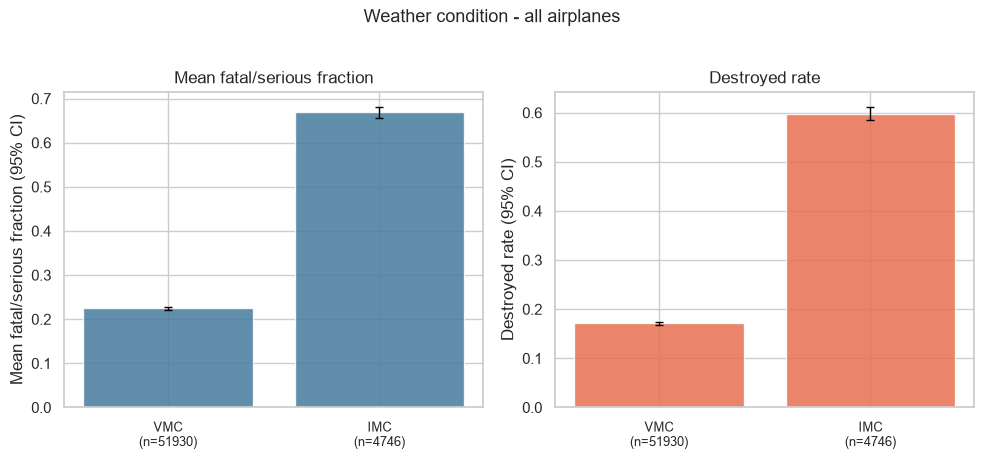

Injury fraction  -> Mann-Whitney U p = 0.00e+00
Destroyed rate   -> chi-square(1) = 4731.9, p = 0.00e+00, Cramer's V = 0.291


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Weather.Condition,,,,,,,
VMC,51930,0.225,0.222,0.229,0.172,0.168,0.175
IMC,4746,0.669,0.656,0.682,0.598,0.584,0.612


In [18]:
w_all = factor_analysis(df, "Weather.Condition", order=["VMC", "IMC"], title="Weather condition - all airplanes", fname="weather_all", figsize=(10, 4.5))
display(w_all[show].round(3))

===== SMALL


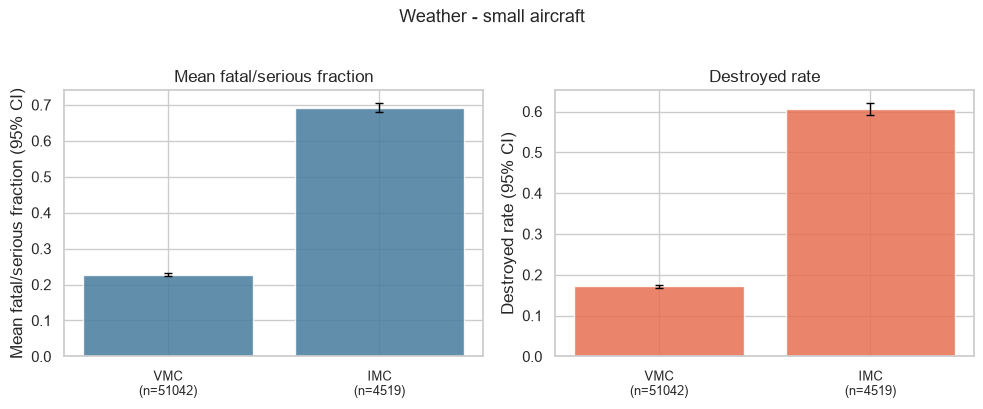

Injury fraction  -> Mann-Whitney U p = 0.00e+00
Destroyed rate   -> chi-square(1) = 4749.4, p = 0.00e+00, Cramer's V = 0.293


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Weather.Condition,,,,,,,
VMC,51042,0.228,0.224,0.231,0.172,0.169,0.175
IMC,4519,0.692,0.679,0.705,0.606,0.592,0.621


===== LARGE


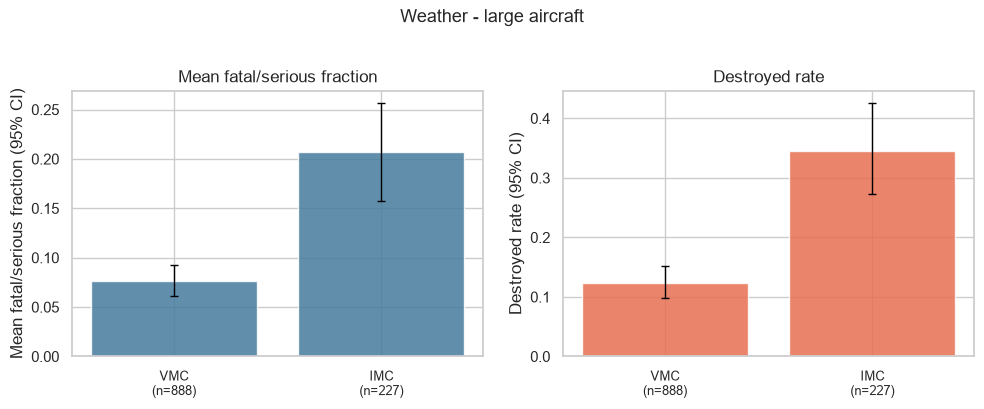

Injury fraction  -> Mann-Whitney U p = 4.35e-09
Destroyed rate   -> chi-square(1) = 39.0, p = 4.31e-10, Cramer's V = 0.236


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Weather.Condition,,,,,,,
VMC,888,0.077,0.061,0.093,0.123,0.098,0.152
IMC,227,0.207,0.158,0.256,0.345,0.272,0.425


In [19]:
# does the weather effect hold within each size class? (guards against a size confounder)
for name, sub in [("SMALL", small), ("LARGE", large)]:
    print("=====", name)
    t = factor_analysis(sub, "Weather.Condition", order=["VMC", "IMC"], title=f"Weather - {name.lower()} aircraft", fname=f"weather_{name.lower()}", figsize=(10, 4))
    display(t[show].round(3))

**Weather condition - discussion**

Accidents in **instrument meteorological conditions (IMC)** are dramatically more severe than those in visual conditions (VMC):

| | n | mean fatal/serious fraction | destroyed rate |
|---|---|---|---|
| VMC | 51,930 | 0.225 (CI 0.222-0.229) | 17.2% |
| IMC | 4,746 | 0.669 (CI 0.656-0.682) | 59.8% |

An IMC accident is ~3x as damaging to the occupants and ~3.5x as likely to destroy the aircraft (Mann-Whitney p < 1e-300; chi-square Cramer's V = 0.29, a medium effect). The effect holds in *both* size classes - small aircraft 0.228 -> 0.692 and 17.2% -> 60.6%; large aircraft 0.077 -> 0.207 (p = 4e-9) and 12.3% -> 34.5% - so it is not an artefact of mixing sizes. Large aircraft suffer much less in both conditions, as expected.

*Interpretation and caveats:* the effect is a severity effect (given an accident), consistent with loss of visual reference leading to uncontrolled flight into terrain at high energy (not directly tested here). We cannot say how often IMC leads to an accident without flight-hours. About 25% of large-aircraft events have no weather recorded (many of them outside the US), so the large-aircraft comparison uses 1,115 of 1,490 events.

### Factor 2: Phase of flight

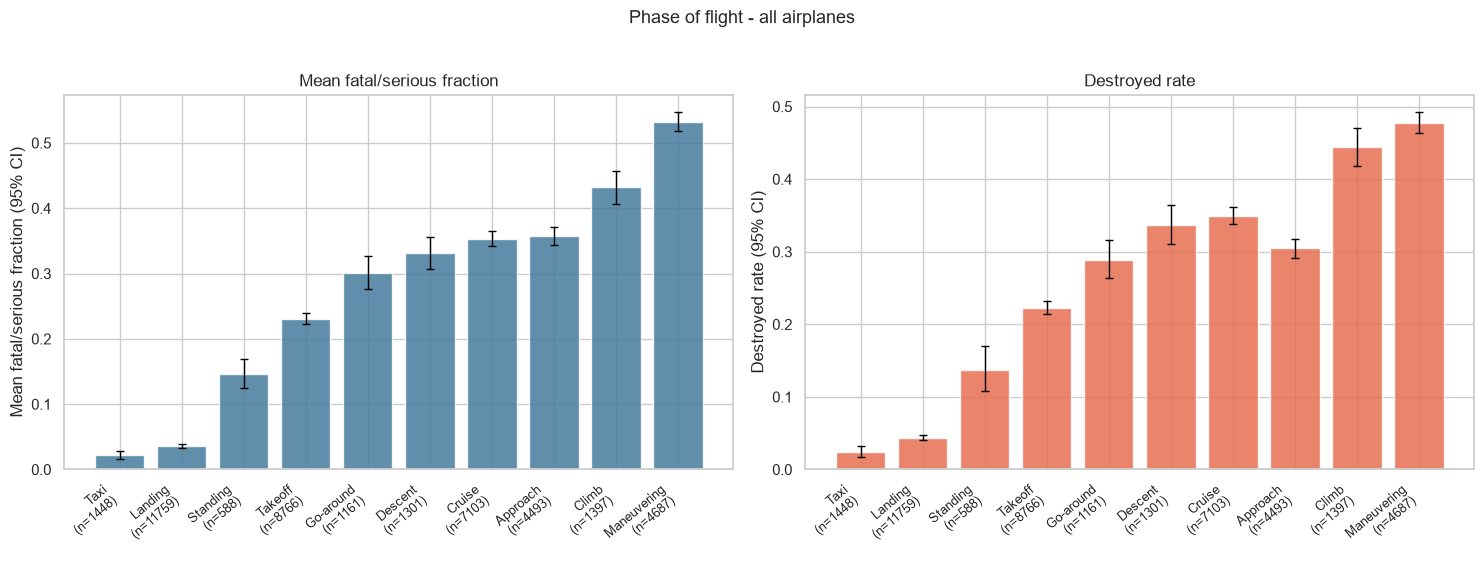

Injury fraction  -> Kruskal-Wallis p = 0.00e+00
Destroyed rate   -> chi-square(9) = 5354.2, p = 0.00e+00, Cramer's V = 0.356


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Broad.phase.of.flight,,,,,,,
Taxi,1448,0.022,0.015,0.028,0.024,0.017,0.033
Landing,11759,0.035,0.032,0.038,0.044,0.040,0.047
Standing,588,0.147,0.124,0.169,0.136,0.108,0.170
Takeoff,8766,0.231,0.222,0.239,0.223,0.214,0.232
Go-around,1161,0.301,0.276,0.327,0.289,0.263,0.316
Descent,1301,0.331,0.306,0.356,0.337,0.311,0.364
Cruise,7103,0.354,0.343,0.364,0.350,0.339,0.361
Approach,4493,0.358,0.344,0.371,0.304,0.291,0.318
Climb,1397,0.432,0.407,0.457,0.444,0.418,0.471


In [20]:
ph_all = factor_analysis(df, "Broad.phase.of.flight", title="Phase of flight - all airplanes", fname="phase_all", figsize=(15, 5.5), rotate=40)
display(ph_all[show].round(3))

===== SMALL


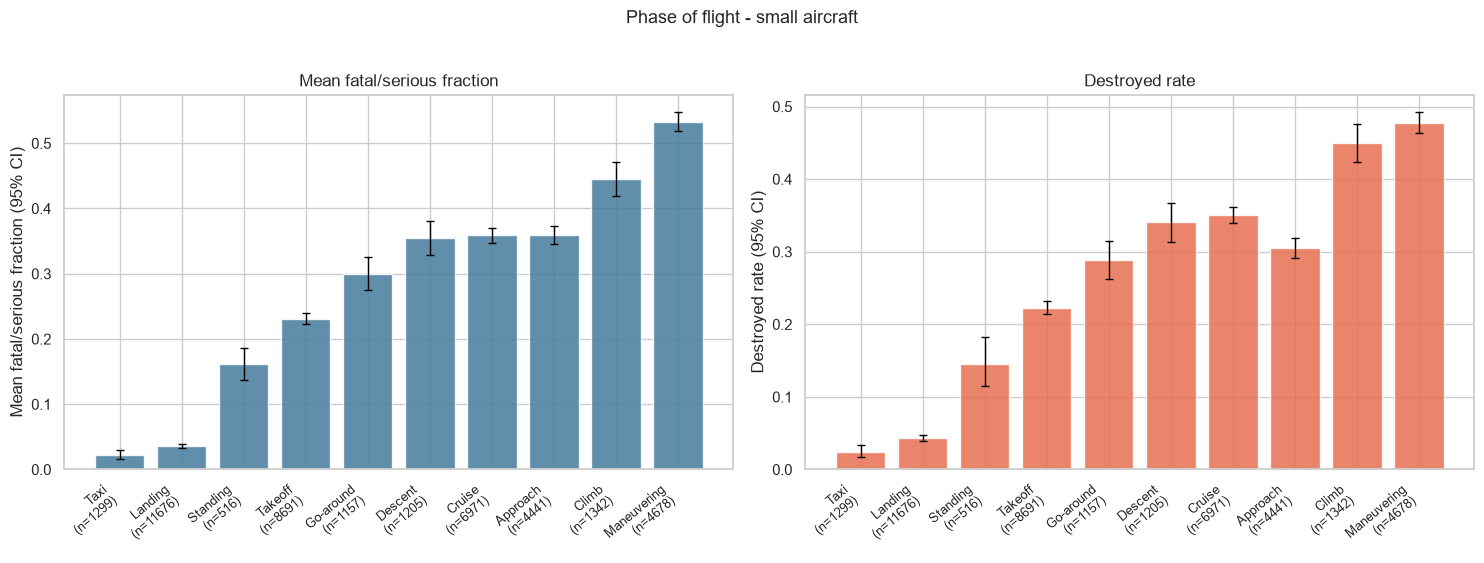

Injury fraction  -> Kruskal-Wallis p = 0.00e+00
Destroyed rate   -> chi-square(9) = 5301.2, p = 0.00e+00, Cramer's V = 0.356


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Broad.phase.of.flight,,,,,,,
Taxi,1299,0.023,0.016,0.029,0.024,0.017,0.034
Landing,11676,0.035,0.032,0.038,0.043,0.040,0.047
Standing,516,0.161,0.136,0.186,0.146,0.115,0.183
Takeoff,8691,0.231,0.223,0.240,0.223,0.214,0.232
Go-around,1157,0.300,0.275,0.326,0.288,0.263,0.315
Descent,1205,0.354,0.328,0.380,0.340,0.314,0.368
Cruise,6971,0.359,0.348,0.370,0.350,0.339,0.362
Approach,4441,0.360,0.346,0.373,0.305,0.292,0.319
Climb,1342,0.445,0.420,0.471,0.450,0.423,0.477


===== LARGE


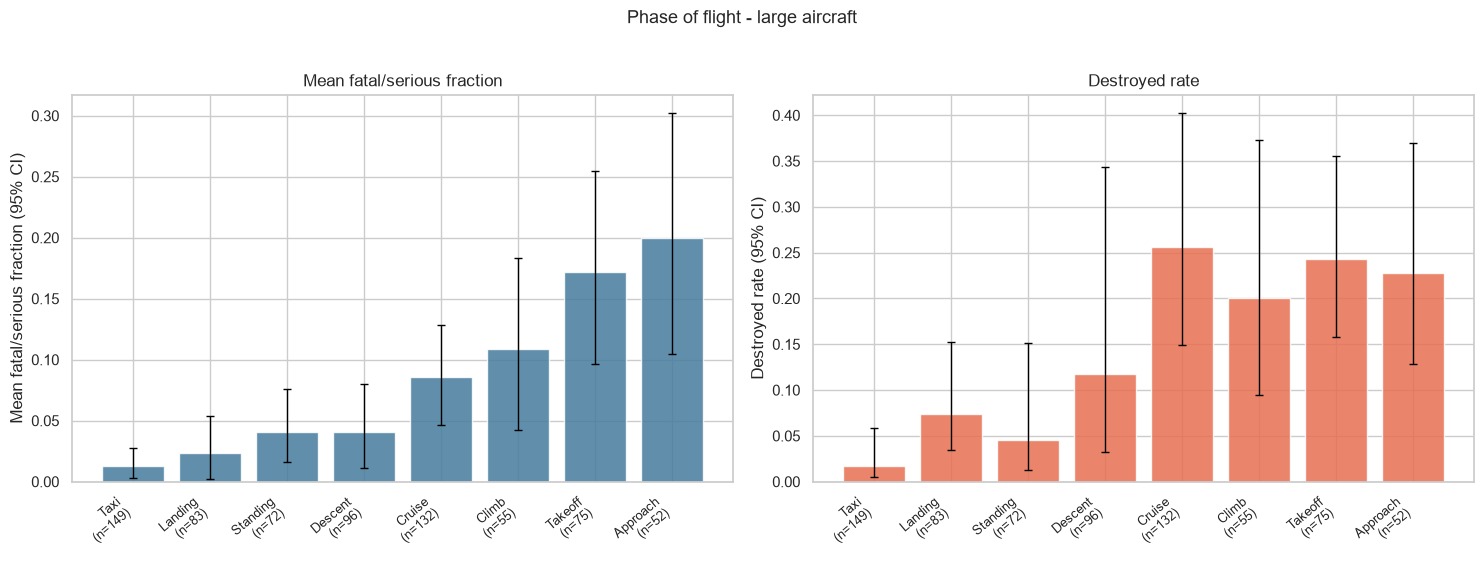

Injury fraction  -> Kruskal-Wallis p = 6.26e-30
Destroyed rate   -> chi-square(7) = 38.8, p = 2.14e-06, Cramer's V = 0.294


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Broad.phase.of.flight,,,,,,,
Taxi,149,0.012,0.003,0.027,0.017,0.005,0.059
Landing,83,0.023,0.002,0.054,0.074,0.034,0.152
Standing,72,0.041,0.016,0.076,0.045,0.013,0.151
Descent,96,0.041,0.011,0.080,0.118,0.033,0.343
Cruise,132,0.085,0.047,0.128,0.256,0.149,0.402
Climb,55,0.109,0.042,0.184,0.200,0.095,0.373
Takeoff,75,0.171,0.097,0.255,0.243,0.158,0.355
Approach,52,0.200,0.105,0.302,0.227,0.128,0.370


In [21]:
for name, sub in [("SMALL", small), ("LARGE", large)]:
    print("=====", name)
    t = factor_analysis(sub, "Broad.phase.of.flight", title=f"Phase of flight - {name.lower()} aircraft", fname=f"phase_{name.lower()}", figsize=(15, 5.5), rotate=40)
    display(t[show].round(3))

**Phase of flight - discussion**

Phase of flight is the strongest factor we tested (Cramer's V = 0.36 for destruction; Kruskal-Wallis p ~ 0 for injury). For all airplanes:

- **Ground / low-energy phases are benign:** Taxi (fraction 0.022, 2.4% destroyed, n=1,448) and Landing (0.035, 4.4%, n=11,759).
- **Take-off is intermediate** (0.231, 22.3%, n=8,766), **cruise, descent and approach are severe** (0.33-0.36 injury, 30-35% destroyed), and **climb (0.432, 44.4%)** and especially **manoeuvring (0.533, 47.8%, n=4,687)** are the worst: in a manoeuvring accident about half of those on board are seriously or fatally hurt.
- Large aircraft show the same ordering at lower levels: taxi 0.012, landing 0.023 (7.4% destroyed), cruise 0.085 (25.6%), take-off 0.171, approach 0.200. Small samples (52-149 per phase, 51% of large events have no phase recorded) make the large-aircraft phases less precise: the most visible pattern is the gap between ground/landing phases and take-off/approach/cruise.

*Interpretation:* accident severity rises with speed, altitude and the time available to cause energy build-up; landing and taxi accidents are mostly low-energy overruns or hard landings that damage but rarely destroy the airplane. *For the make comparison* this matters: makes used mainly for low-level operations (agricultural, aerobatic, sport) will be over-represented in the maneuvering/take-off phases, which is another reason for the makes and types ranking above to be read as indicative rather than causal.

### Factor 3: Number of engines (and engine type)

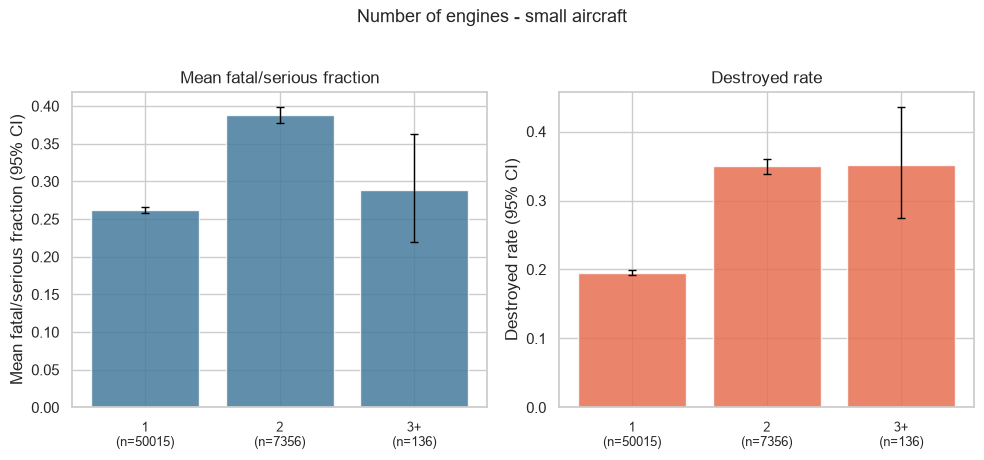

Injury fraction  -> Kruskal-Wallis p = 2.32e-124
Destroyed rate   -> chi-square(2) = 906.2, p = 1.70e-197, Cramer's V = 0.126


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Engines.Grp,,,,,,,
1,50015,0.262,0.259,0.266,0.195,0.192,0.199
2,7356,0.388,0.378,0.399,0.349,0.339,0.361
3+,136,0.288,0.219,0.363,0.351,0.275,0.436


LARGE aircraft


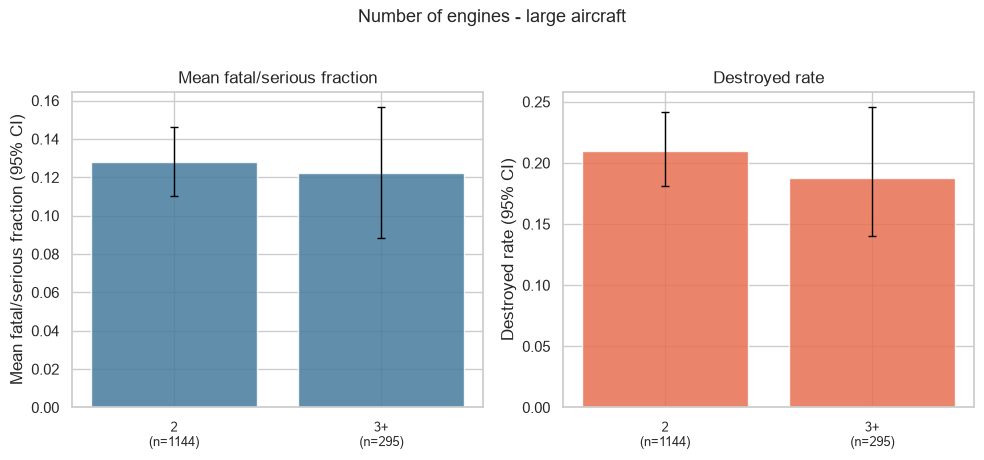

Injury fraction  -> Mann-Whitney U p = 3.68e-01
Destroyed rate   -> chi-square(1) = 0.4, p = 5.44e-01, Cramer's V = 0.020


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Engines.Grp,,,,,,,
2,1144,0.128,0.110,0.146,0.210,0.181,0.242
3+,295,0.122,0.088,0.157,0.188,0.140,0.246


In [22]:
df["Engines.Grp"] = df["Number.of.Engines"].map({1.0: "1", 2.0: "2", 3.0: "3+", 4.0: "3+"})
small["Engines.Grp"] = small["Number.of.Engines"].map({1.0: "1", 2.0: "2", 3.0: "3+", 4.0: "3+"})
large["Engines.Grp"] = large["Number.of.Engines"].map({1.0: "1", 2.0: "2", 3.0: "3+", 4.0: "3+"})
ne = factor_analysis(small, "Engines.Grp", order=["1", "2", "3+"], title="Number of engines - small aircraft", fname="engines_small", figsize=(10, 4.5))
display(ne[show].round(3))
print("LARGE aircraft")
ne_l = factor_analysis(large, "Engines.Grp", order=["1", "2", "3+"], title="Number of engines - large aircraft", fname="engines_large", figsize=(10, 4.5))
display(ne_l[show].round(3))

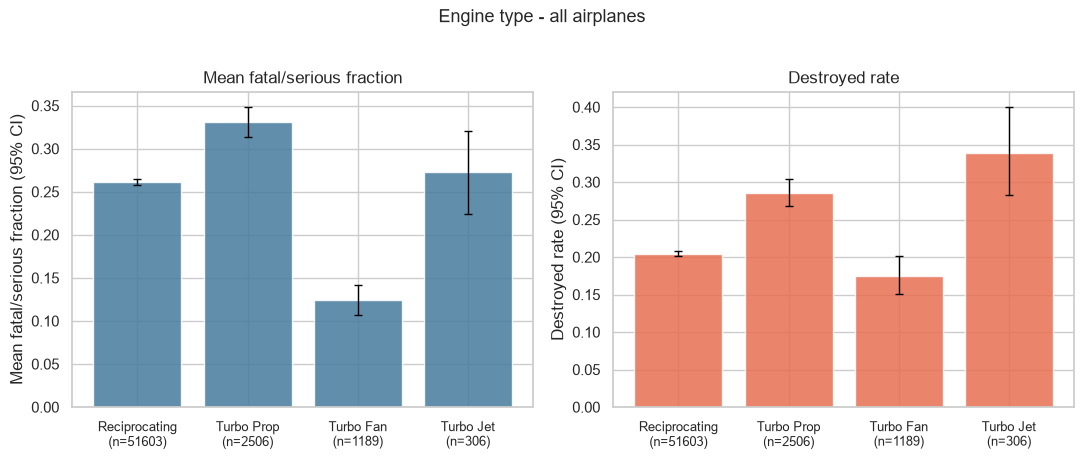

Injury fraction  -> Kruskal-Wallis p = 3.70e-28
Destroyed rate   -> chi-square(3) = 124.5, p = 8.13e-27, Cramer's V = 0.048


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Engine.Type,,,,,,,
Reciprocating,51603,0.262,0.258,0.265,0.205,0.201,0.208
Turbo Prop,2506,0.331,0.313,0.349,0.286,0.268,0.304
Turbo Fan,1189,0.124,0.107,0.141,0.175,0.150,0.202
Turbo Jet,306,0.273,0.225,0.321,0.339,0.282,0.401


SMALL aircraft only


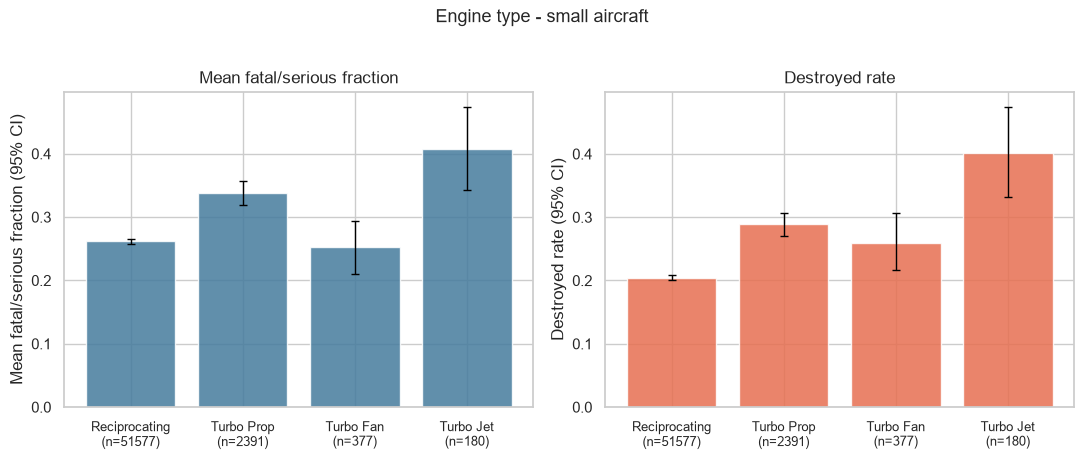

Injury fraction  -> Kruskal-Wallis p = 2.57e-23
Destroyed rate   -> chi-square(3) = 141.7, p = 1.64e-30, Cramer's V = 0.051


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Engine.Type,,,,,,,
Reciprocating,51577,0.262,0.258,0.265,0.205,0.201,0.208
Turbo Prop,2391,0.338,0.319,0.356,0.289,0.271,0.307
Turbo Fan,377,0.252,0.211,0.293,0.259,0.216,0.307
Turbo Jet,180,0.407,0.342,0.474,0.401,0.332,0.475


In [23]:
et = factor_analysis(df, "Engine.Type", order=["Reciprocating", "Turbo Prop", "Turbo Fan", "Turbo Jet"], title="Engine type - all airplanes", fname="engine_type", figsize=(11, 4.5))
display(et[show].round(3))
# engine type is strongly tied to size, so look at small aircraft only for a like-for-like comparison
print("SMALL aircraft only")
et_s = factor_analysis(small, "Engine.Type", order=["Reciprocating", "Turbo Prop", "Turbo Fan", "Turbo Jet"], title="Engine type - small aircraft", fname="engine_type_small", figsize=(11, 4.5))
display(et_s[show].round(3))

**Number of engines and engine type - discussion**

- **Small aircraft:** twin-engine aircraft have markedly worse outcomes than single-engine aircraft (fatal/serious fraction **0.388 vs 0.262**; destroyed **34.9% vs 19.5%**; n = 7,356 vs 50,015; Kruskal-Wallis p ~ 1e-124, Cramer's V = 0.13). A naive reading ("more engines = safer redundancy") is therefore *not* supported. However, the twin-engine result is strongly **confounded**: 20.4% of twin-engine accidents occurred in IMC (vs 6.4% for singles) and twins are used far more for business/positioning/ferry flights (23% vs 6%), which are themselves associated with worse outcomes (see purpose below). The number of engines is therefore a marker for a riskier operating profile, not an independent cause.
- **Large aircraft:** two-engine (0.128, 21.0% destroyed, n=1,144) and three/four-engine (0.122, 18.8%, n=295) aircraft are indistinguishable (p = 0.37 and p = 0.54, Cramer's V = 0.02), so engine count should not be used to select large aircraft.
- **Engine type:** among small aircraft, **piston (reciprocating)** engines have the best outcomes (0.262, 20.5% destroyed), **turboprops** are worse (0.338, 28.9%, n=2,391) and **turbojets** are worst (0.407, 40.1%, n=180); turbofans are about equal to pistons (0.252, n=377). Across *all* aircraft turbofans look best (0.124) simply because that engine type identifies the large airliners. Effects are statistically significant but small (V ~ 0.05) - higher-performance, higher-energy aircraft crash with more energy.

### Factor 4: Purpose of flight

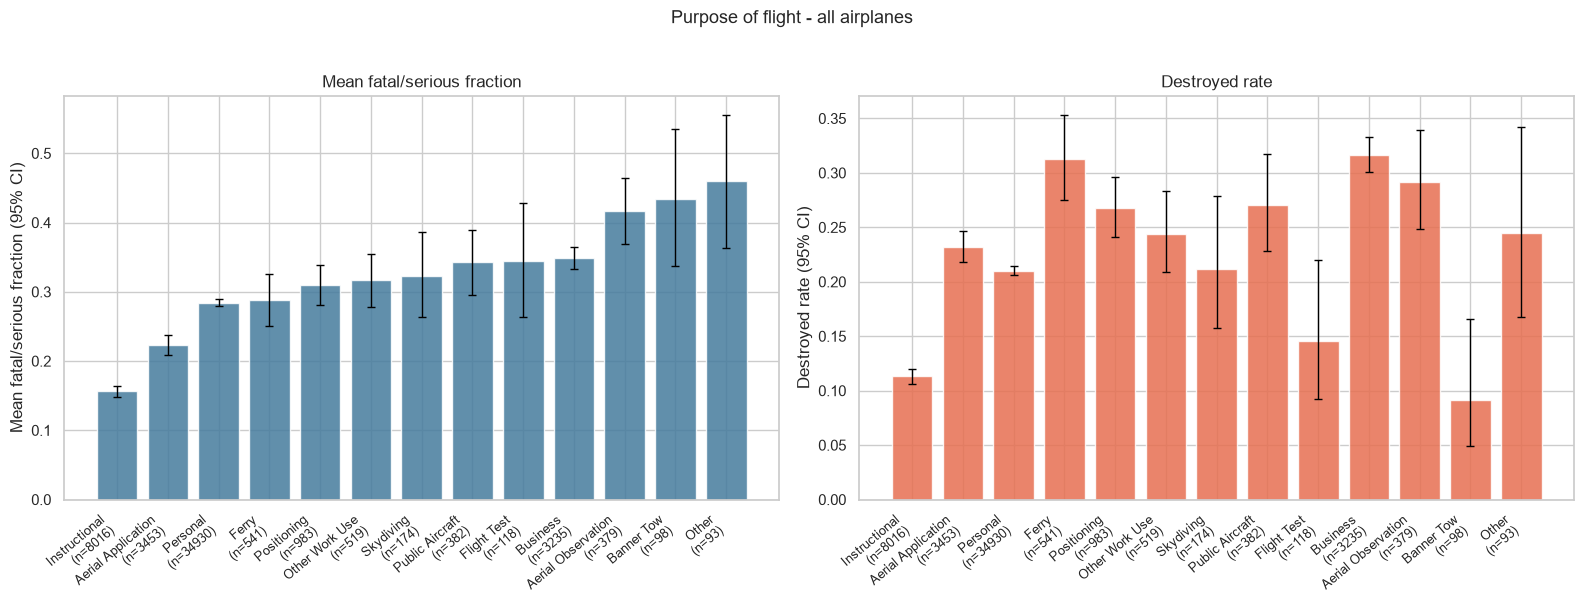

Injury fraction  -> Kruskal-Wallis p = 8.29e-188
Destroyed rate   -> chi-square(12) = 780.4, p = 2.61e-159, Cramer's V = 0.122


,n_events,fs_mean,fs_lo,fs_hi,destroyed_rate,dest_lo,dest_hi
Purpose.of.flight,,,,,,,
Instructional,8016,0.156,0.148,0.164,0.113,0.106,0.120
Aerial Application,3453,0.223,0.209,0.237,0.232,0.218,0.246
Personal,34930,0.285,0.280,0.289,0.210,0.206,0.214
Ferry,541,0.288,0.250,0.325,0.313,0.275,0.353
Positioning,983,0.310,0.281,0.338,0.268,0.241,0.296
Other Work Use,519,0.316,0.278,0.355,0.244,0.209,0.283
Skydiving,174,0.322,0.263,0.387,0.212,0.157,0.279
Public Aircraft,382,0.343,0.296,0.389,0.270,0.228,0.317
Flight Test,118,0.345,0.264,0.428,0.145,0.093,0.220


In [24]:
pf = factor_analysis(df, "Purpose.of.flight", title="Purpose of flight - all airplanes", fname="purpose_all", figsize=(16, 6), rotate=40)
display(pf[show].round(3))

**Purpose of flight - discussion**

Purpose of flight is associated with clear differences (Cramer's V = 0.12; Kruskal-Wallis p < 1e-180):
- **Instructional flying is by far the safest** (fatal/serious fraction **0.156**, **11.3%** destroyed, n=8,016), versus personal flights (0.285, 21.0%, n=34,930).
- **Business flights are the most damaging of the high-volume purposes** (0.349, **31.6%** destroyed, n=3,235), followed by ferry (31.3% destroyed), public aircraft (0.343) and positioning (0.310).
- Low-volume purposes with very high injury fractions (banner tow 0.434, n=98; aerial observation 0.417, n=379; "other" 0.461, n=93) have wide CIs and should be treated cautiously. Banner tow aircraft are rarely destroyed (9.2%) but injuries are severe.
- A plausible explanation is that instruction takes place in docile, low-speed aircraft, close to an airfield, with an instructor on board, whereas business flying involves more demanding conditions (IMC, cross-country, higher-performance aircraft) - consistent with the weather and engine findings above, although these links are not causal tests.

**Implication for insurers:** operator/usage profile (instructional vs business, VMC vs IMC) matters at least as much as the make, and should be priced alongside the make/type recommendations.

## Summary and recommendations

**Small aircraft (fewer than ~20 people)**
1. **Maule (M-4, M-4-220C, MX-7-235 and related)** is the most robust recommendation: 569 events, injury fraction 0.154 vs 0.281 for the rest of the fleet, destroyed 9.3% vs 21.7%, both significant after multiple-test correction.
2. **Waco, Helio and Schweizer/Grumman-Schweizer** have the lowest occupant-injury fractions; **Aviat and Diamond** have the lowest destruction rates (7.0%, 7.5%). These are niche or vintage designs, so exposure and usage differ from the mainstream fleet.
3. Among mainstream high-volume makes, **Cessna is safer than Piper** in severity terms, and **Cirrus, Mitsubishi, Socata, Beech, Mooney and Aero Commander** are on the higher-risk side.

**Large aircraft (20+ people)**
1. **Boeing, Airbus, Embraer, Bombardier and McDonnell Douglas** form a comparable low-risk tier (0.106-0.139) - the data cannot rank one above the others (p = 0.32).
2. Preferred types: **Boeing 757 family, 717-200, 777, MD-80/MD-88, Airbus A320-232**. Less favourable: **Boeing 737-200/-400, A320 (unspecified variant), DC-3, DHC-6-300, Beech 1900**.

**General factors**
- **Weather:** IMC multiplies the destroyed rate by ~3.5 and the fatal/serious fraction by ~3.
- **Phase of flight:** landing/taxi accidents are nearly harmless (< 5% destroyed); manoeuvring, climb and cruise accidents are the worst (35-48% destroyed).
- **Engines/purpose:** twin and turbine small aircraft and business flying show worse outcomes (partly confounded by IMC and operation type); instructional flying is the safest purpose.

**Limitations.** No exposure data (hours/departures) so only severity-given-accident can be measured; the dataset is US-centric (NTSB); persons on board includes crew; the aircraft category was imputed for pre-2008 events; sample sizes for individual types are small (10-30), so rankings among types are indicative; observational data cannot prove causation.